# Applying Data Analytics and Machine Learning to Study the Maxwell-Boltzmann Speed Distribution in Ideal Gases

**Student:** Reda Ghafla (2026023) · **Programme:** HDip in Data Analytics for Business · **Institution:** CCT College Dublin
**Supervisor:** Taufique Ahmed

---

### Table of Contents
1. Introduction
2. Research Aim and Objectives
3. Theoretical Physics and Mathematical Foundation
4. Data Generation and Dataset Description
5. Data Cleaning and Preparation
6. Exploratory Data Analysis (EDA)
7. Statistical Analysis and Validation
8. Feature Engineering
9. Machine Learning
10. Model Evaluation and Comparison
11. PCA and Dimensionality Reduction
12. Physical Interpretation of Results
13. Discussion
14. Limitations
15. Conclusion
16. References


## 1. Introduction

### 1.1 Motivation

Before I started the HDip in Data Analytics at CCT College Dublin, I studied Physics in Morocco. One topic I always liked is the **Maxwell-Boltzmann speed distribution**. It describes how fast the molecules of a gas move at a given temperature.

The topic is interesting for a data analyst because it is a **probability distribution**. A gas contains a huge number of molecules (about $2.5 \times 10^{25}$ in one cubic metre of air at room temperature and normal pressure, from $n = P/k_BT$). We cannot follow every molecule, so physics describes the gas with **statistics**: averages, spreads and probabilities. These are the same tools we use in data analytics.

In this project, I use Python to simulate the speeds of nitrogen (N₂) molecules at four temperatures. Then I analyse the data with the full data analytics workflow: exploratory analysis, statistical tests, Machine Learning and PCA.

### 1.2 Physics and Data Science

Physics and Machine Learning look at data from two different directions:

| | Physics (theory) | Machine Learning (data) |
|---|---|---|
| Starting point | Laws and equations | Observations |
| Method | Derive the result mathematically | Learn patterns from examples |
| Result | An exact formula, e.g. $v_{mean} = \sqrt{8k_BT/\pi m}$ | A fitted model, e.g. $\hat{y} = a\cdot x + b$ |

This project uses **both directions at the same time**. Because we know the true physical law, we can check whether the Machine Learning models discover the correct physics. For example, does Linear Regression find the theoretical slope? Can a Random Forest tell the temperature from the speeds? This makes a simulated physical system a very good "laboratory" for understanding how ML models work, where they succeed and where they fail.

**Important:** all data in this project is **simulated** from a known equation. The project does not measure a real gas. It shows how data analytics methods behave on data with a known physical structure. I discuss this limitation in Sections 10.3 and 14.

### 1.3 CRISP-DM Roadmap

As described in my proposal, the project follows the **CRISP-DM** framework (Chapman et al., 2000), adapted for a physics simulation. The six phases and the notebook sections are:

| CRISP-DM phase | What we do | Notebook section |
|---|---|---|
| 1. Research Understanding | Define the physical system (N₂, ideal gas, 4 temperatures) and the theory | 1, 2, 3 |
| 2. Data Generation | Simulate molecular speeds with `scipy.stats.maxwell` | 4 |
| 3. Data Preparation | Check, clean and prepare the data; build features | 5, 8 |
| 4. Exploratory Data Analysis | Statistics and visualisations; statistical validation | 6, 7 |
| 5. Modelling | Linear Regression, Random Forest, K-Means, extra models, PCA | 9, 11 |
| 6. Evaluation | Compare models, interpret the physics, answer the research questions | 10, 12–15 |

CRISP-DM is not a straight line. If a result in the Evaluation phase shows a problem (for example, data leakage), we go back to an earlier phase and fix it.

### 1.4 Libraries and Reproducibility

**A. What are we doing?**
We import all the Python libraries for the project. We also fix the random seed and set one style for all graphs.

**B. Why are we doing it?**
- Putting all imports in one place makes the notebook easy to read and to run again.
- A **fixed random seed** makes the simulation **reproducible**. Every time the notebook runs, the "random" numbers are exactly the same, so the results in this report never change. This is a basic rule of good scientific practice.

**C. Mathematical foundation**
A computer does not create truly random numbers. It uses a **pseudo-random number generator**: a deterministic algorithm that produces a sequence of numbers that *look* random. The seed is the starting point of the sequence. The same seed always gives the same sequence.

**D. Python explanation**
- `numpy` (Harris et al., 2020): arrays and fast mathematics.
- `pandas` (McKinney, 2010): tables (DataFrames).
- `scipy` (Virtanen et al., 2020): `scipy.stats` for distributions and statistical tests, `scipy.constants` for the official physical constants, and `scipy.integrate` for numerical integration.
- `matplotlib` (Hunter, 2007) and `seaborn` (Waskom, 2021): graphs.
- `np.random.default_rng(SEED)` creates a modern NumPy random generator with our seed.
- `TEMP_COLORS` gives each temperature one fixed colour, from blue (cold) to red (hot). We use these colours in every graph, so a reader always knows which temperature is shown.
- We also create a `figures/` folder, so every graph can be saved for the final Word report.

**E. Expected result**
No errors, and a printed list of the library versions. The versions are important because results can change slightly between versions.

In [1]:
# --- Core libraries ---
import os
import platform
import numpy as np
import pandas as pd
import scipy
from scipy import stats, constants, integrate
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

# --- Reproducibility ---
SEED = 42                                  # one seed for the whole project
rng = np.random.default_rng(SEED)          # NumPy random generator

# --- The four temperatures of the study (Kelvin) ---
TEMPERATURES = [100, 300, 500, 1000]

# --- One colour per temperature: blue = cold, red = hot ---
TEMP_COLORS = {100: "#2166ac", 300: "#67a9cf", 500: "#ef8a62", 1000: "#b2182b"}

# --- Graph style ---
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.titleweight": "bold"})
# Normal numbers with 4 decimals; very small or very large numbers (e.g. 4.65e-26 kg) in scientific notation
pd.set_option("display.float_format",
              lambda x: f"{x:,.4f}" if (x == 0 or 1e-3 <= abs(x) < 1e7) else f"{x:.4e}")

# --- Folder for saved figures (used in the final report) ---
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

print(f"Python       {platform.python_version()}")
for lib in (np, pd, scipy, matplotlib, sns, sklearn):
    print(f"{lib.__name__:<12} {lib.__version__}")
print(f"Random seed  {SEED}")

Python       3.12.10
numpy        2.5.4
pandas       3.1.0
scipy        1.18.1
matplotlib   3.11.2
seaborn      0.13.2
sklearn      1.9.1
Random seed  42


**Result.** All libraries were imported without errors, and the versions are printed above. Anyone who wants to repeat this analysis should use the same (or very similar) versions. The seed `42` is now fixed, so all random numbers in this notebook are reproducible.

## 2. Research Aim and Objectives

### 2.1 Research Aim

The aim of this research is to **build a data pipeline for simulating and classifying gas particle speeds at different temperatures**. This pipeline is a practical bridge between thermodynamic theory and Machine Learning.

### 2.2 Research Objectives

The objectives come directly from my approved proposal:

1. **Simulate** speed data for an ideal gas (N₂) at 100 K, 300 K, 500 K and 1000 K using `scipy.stats.maxwell`, to create a complete dataset. → *Section 4*
2. **Conduct Exploratory Data Analysis (EDA)** to show how the distributions shift and flatten as the temperature increases. → *Section 6*
3. **Perform statistical validation** with the Shapiro-Wilk test and the Kolmogorov-Smirnov test, to check data quality and distribution fit. → *Section 7*
4. **Implement and evaluate Machine Learning models**: Random Forest Classifier, Linear Regression and K-Means Clustering. → *Sections 9 and 10*
5. **Apply Principal Component Analysis (PCA)** to reduce dimensionality and visualise the data in 2D while keeping the physical patterns. → *Section 11*

### 2.3 Research Questions

- **RQ1:** How accurately can Machine Learning models classify gas temperature based on simulated speed distributions and their statistical features?
- **RQ2:** Can PCA preserve the meaningful physical patterns in thermodynamic datasets while reducing the number of features?

**How we answer RQ1.** The question mentions two things: the *speed distributions* and their *statistical features*. So we study classification at two levels:

| Level | One observation is… | Main features |
|---|---|---|
| **A. Molecule level** | the speed of one molecule | speed (and values calculated from it) |
| **B. Sample level** | a random group of *n* molecules from the same gas | statistics of the group: mean, median, standard deviation, skewness, kurtosis, percentiles |

Level A shows how much information one molecule carries. Level B shows how much information a *distribution* carries. Comparing the two levels is a central part of the answer to RQ1.

### 2.4 Hypotheses

Before we look at any data, we write down what physics predicts. Later sections test each prediction with the real Python output. A good scientist writes predictions **before** the analysis, so the results cannot change the questions.

| # | Prediction from theory | Tested in |
|---|---|---|
| H1 | The simulated speeds follow the Maxwell-Boltzmann distribution, so the KS test should **not** reject the theoretical distribution. | 7.3 |
| H2 | Molecular speeds are **not** normally distributed (the distribution is right-skewed), so the Shapiro-Wilk test should reject normality. | 7.2 |
| H3 | The mean speed grows with $\sqrt{T}$, not with $T$. A regression on $\sqrt{T}$ should fit better than a regression on $T$, with a slope close to $\sqrt{8k_B/\pi m}$. | 9.1 |
| H4 | The distributions overlap, so classifying the temperature from **one** molecule's speed is limited. Classification from the **statistics of a sample** of molecules should be much more accurate. | 9.2 |
| H5 | K-Means can find the temperature groups without labels when it uses sample-level statistics, but not from single molecular speeds. | 9.3 |
| H6 | Most of the variation in the sample-level features is caused by one physical factor, the temperature. So the first principal component should explain most of the variance, and the 2D PCA plot should keep the temperature groups apart. | 11 |

## 3. Theoretical Physics and Mathematical Foundation

This section builds the physics **before** we touch any data. Every later result (EDA, tests, Machine Learning) is compared with the equations derived here. The main references are Blundell and Blundell (2010) and Reif (2009).

We use these symbols in the whole notebook:

| Symbol | Meaning | Unit |
|---|---|---|
| $v$ | speed of one molecule (always $\ge 0$) | m/s |
| $v_x, v_y, v_z$ | velocity components (can be negative) | m/s |
| $m$ | mass of **one** N₂ molecule | kg |
| $k_B$ | Boltzmann constant $= 1.380649 \times 10^{-23}$ | J/K |
| $T$ | absolute temperature | K |
| $E_k$ | translational kinetic energy of one molecule | J |
| $f(v)$ | probability density function (PDF) of the speed | s/m |

### 3.1 From the Boltzmann Distribution to Maxwell-Boltzmann

**Step 1 – The Boltzmann distribution.**
Statistical mechanics says that, in thermal equilibrium at temperature $T$, the probability that a system is in a state with energy $E_i$ is

$$P(E_i) = \frac{1}{Z}\, e^{-E_i / k_B T}$$

- The factor $e^{-E_i/k_BT}$ is the **Boltzmann factor**. States with high energy are **less probable**, because the exponential becomes very small when $E_i \gg k_BT$.
- $k_BT$ is the "typical energy" that the surroundings can give to a molecule. A higher temperature makes high-energy states more accessible.
- $Z = \sum_i e^{-E_i/k_BT}$ is the **partition function**. It is a normalisation constant, so that all probabilities add up to 1.

**Step 2 – Apply it to one gas molecule.**
In an **ideal gas** the molecules do not attract or repel each other. The only energy that depends on the motion is the translational kinetic energy:

$$E_k = \tfrac{1}{2} m \left(v_x^2 + v_y^2 + v_z^2\right)$$

**Step 3 – Each velocity component is a normal distribution.**
Put $E_k$ into the Boltzmann factor. The exponential of a sum is a product of exponentials, so the three directions are **independent**:

$$f(v_x, v_y, v_z) \propto e^{-m v_x^2/2k_BT}\cdot e^{-m v_y^2/2k_BT}\cdot e^{-m v_z^2/2k_BT}$$

Each factor is a **normal (Gaussian) distribution** with mean 0 and variance $\sigma^2 = k_BT/m$. After normalisation:

$$f(v_x) = \sqrt{\frac{m}{2\pi k_BT}}\; e^{-m v_x^2/2k_BT}$$

This is a nice link to my ML course (lesson 1.3.4, continuous distributions): each **velocity component** of a gas molecule is a normal random variable.

**Step 4 – From velocity to speed.**
The speed is the length of the velocity vector: $v = \sqrt{v_x^2+v_y^2+v_z^2}$. Many different velocity vectors have the same speed $v$. In 3D velocity space, they all lie on a **sphere of radius $v$**, and a thin spherical shell has volume $4\pi v^2\,dv$. So we multiply the velocity probability by the shell area $4\pi v^2$:

$$f(v)\,dv = 4\pi v^2 \left(\frac{m}{2\pi k_BT}\right)^{3/2} e^{-m v^2/2k_BT}\,dv$$

This is the **Maxwell-Boltzmann speed distribution**.

**Connection to statistics.** If $v_x, v_y, v_z$ are independent normal variables with the same $\sigma$, then $v/\sigma$ follows a **chi distribution with 3 degrees of freedom**. In SciPy, this distribution is called `scipy.stats.maxwell`. That is why SciPy can generate our data directly (Section 4.2).

### 3.2 The Maxwell-Boltzmann Speed Distribution

$$\boxed{\,f(v) = 4\pi \left(\frac{m}{2\pi k_BT}\right)^{3/2} v^2\, \exp\!\left(-\frac{m v^2}{2k_BT}\right)\,}$$

**What does the equation represent?**
$f(v)$ is a **probability density**. The probability that a molecule has a speed between $v_1$ and $v_2$ is the area under the curve:

$$P(v_1 \le v \le v_2) = \int_{v_1}^{v_2} f(v)\,dv$$

The value $f(v)$ itself is *not* a probability. Its unit is s/m, so only $f(v)\,dv$ (an area) is a probability.

**The three parts of the equation**

| Part | Meaning |
|---|---|
| $4\pi\left(\frac{m}{2\pi k_BT}\right)^{3/2}$ | Normalisation constant. It makes the total area equal to 1. |
| $v^2$ | **Geometric factor.** The number of velocity directions with speed $v$ grows like the area of a sphere, $4\pi v^2$. It pushes probability **up** at higher speeds. |
| $\exp\left(-\frac{mv^2}{2k_BT}\right)$ | **Boltzmann factor.** High speed means high kinetic energy, and high energy is less probable. It pushes probability **down** at higher speeds. |

**Why is there a peak?** For small $v$, the $v^2$ term wins and $f(v)$ grows. For large $v$, the exponential wins and $f(v)$ goes to zero very fast. The competition between the two terms creates a single maximum, the **most probable speed**.

**Why is the distribution not symmetrical?**
- On the left, the speed cannot be negative, so the curve starts at $v = 0$ and rises like $v^2$.
- On the right, there is no upper limit, and the curve has a long **tail** of fast molecules.

So the distribution is **right-skewed** (positive skewness). This is why the mean is larger than the most probable speed. A normal distribution is always symmetric, so molecular speeds are **not normal**. This is the basis of hypothesis H2.

**What happens when the temperature increases?**
The temperature appears only in the combination $k_BT/m$. A higher $T$ gives a "wider" exponential, so:
1. The peak moves to **higher speeds** (molecules move faster on average).
2. The distribution becomes **wider** (more spread between slow and fast molecules).
3. The peak becomes **lower**. The total area must stay equal to 1, so a wider curve must be flatter.

This is exactly the "shift and flatten" behaviour that objective 2 asks us to show with EDA.

**Normalisation check (mathematics).** Let $\alpha = \dfrac{m}{2k_BT}$. Then $f(v) = 4\pi\left(\frac{\alpha}{\pi}\right)^{3/2} v^2 e^{-\alpha v^2}$. We use the standard Gaussian integral (ML course, lesson 1.2.6):

$$\int_0^\infty v^2 e^{-\alpha v^2}\,dv = \frac{\sqrt{\pi}}{4}\,\alpha^{-3/2}$$

$$\int_0^\infty f(v)\,dv = 4\pi\,\frac{\alpha^{3/2}}{\pi^{3/2}}\cdot\frac{\sqrt{\pi}}{4}\,\alpha^{-3/2} = \frac{4\pi\sqrt{\pi}}{4\pi^{3/2}} = 1 \;\checkmark$$

The total probability is exactly 1, as required for a PDF.

### 3.3 Characteristic Speeds: Most Probable, Mean and RMS

A distribution can be summarised by different "typical" values. For molecular speeds, physics uses three of them. We keep the notation $\alpha = m / 2k_BT$.

---

#### (a) Most probable speed $v_{mp}$: the peak of the curve

**Derivation.** The peak is where the derivative is zero (ML course, lessons 1.2.2 and 1.2.5). The constant does not change the position of the peak, so we only differentiate $g(v) = v^2 e^{-\alpha v^2}$ with the product rule:

$$g'(v) = 2v\,e^{-\alpha v^2} + v^2\,(-2\alpha v)\,e^{-\alpha v^2} = 2v\,e^{-\alpha v^2}\left(1 - \alpha v^2\right)$$

$g'(v) = 0$ for $v > 0$ only when $1 - \alpha v^2 = 0$, so $v^2 = 1/\alpha = 2k_BT/m$:

$$\boxed{v_{mp} = \sqrt{\frac{2k_BT}{m}}}$$

**Physical meaning.** If you pick one molecule, its speed is most likely to be near $v_{mp}$. It is the **mode** of the distribution.

---

#### (b) Mean speed $v_{mean}$: the average speed

**Derivation.** The mean is the expected value $E[v] = \int_0^\infty v\,f(v)\,dv$ (lesson 1.2.6, expectations). We need the integral $\int_0^\infty v^3 e^{-\alpha v^2}dv = \dfrac{1}{2\alpha^2}$ (substitute $u = v^2$):

$$v_{mean} = 4\pi\left(\frac{\alpha}{\pi}\right)^{3/2}\cdot\frac{1}{2\alpha^2} = \frac{2}{\sqrt{\pi\alpha}} = 2\sqrt{\frac{2k_BT}{\pi m}}$$

$$\boxed{v_{mean} = \sqrt{\frac{8k_BT}{\pi m}}}$$

**Physical meaning.** This is the arithmetic average of all molecular speeds. The **sample mean** of our simulated data should be very close to it (Law of Large Numbers, lesson 1.3.6). In Section 9.1, Linear Regression will try to learn this formula from data.

---

#### (c) Root-mean-square speed $v_{rms}$: linked to energy

**Derivation.** First we calculate the mean of $v^2$, using $\int_0^\infty v^4 e^{-\alpha v^2}dv = \dfrac{3\sqrt{\pi}}{8}\,\alpha^{-5/2}$:

$$\langle v^2\rangle = 4\pi\left(\frac{\alpha}{\pi}\right)^{3/2}\cdot\frac{3\sqrt{\pi}}{8}\,\alpha^{-5/2} = \frac{3}{2\alpha} = \frac{3k_BT}{m}$$

The RMS speed is the square root of this mean:

$$\boxed{v_{rms} = \sqrt{\langle v^2\rangle} = \sqrt{\frac{3k_BT}{m}}}$$

**Physical meaning.** $v_{rms}$ is the speed that gives the **average kinetic energy** (Section 3.4). Squaring gives more weight to fast molecules, so $v_{rms}$ is the largest of the three speeds.

---

#### Relationship with temperature

All three speeds have the same form, $v = \text{constant}\times\sqrt{T/m}$:

$$v \propto \sqrt{T}$$

- If the temperature is multiplied by 4, the speeds are only multiplied by $\sqrt{4} = 2$.
- The relationship between $v$ and $T$ is **not linear**. It is linear between $v$ and $\sqrt{T}$. This is very important for the Linear Regression in Section 9.1 (hypothesis H3).
- Heavier molecules are slower ($v \propto 1/\sqrt{m}$).

The ratio between the three speeds does **not** depend on temperature or mass:

$$v_{mp} : v_{mean} : v_{rms} = \sqrt{2} : \sqrt{8/\pi} : \sqrt{3} \approx 1 : 1.128 : 1.225$$

So the order is always $v_{mp} < v_{mean} < v_{rms}$. Two different reasons explain this order:
- $v_{mp} < v_{mean}$ because the distribution is **right-skewed**: the long tail of fast molecules pulls the mean to the right of the peak.
- $v_{mean} < v_{rms}$ is true for **any** distribution that is not a single value, because $\langle v^2\rangle - \langle v\rangle^2 = \sigma_v^2 > 0$ (the variance is positive).

### 3.4 Kinetic Energy and Temperature

The kinetic energy of one molecule is

$$E_k = \tfrac{1}{2} m v^2$$

Its average follows directly from $\langle v^2\rangle$ in Section 3.3(c):

$$\langle E_k\rangle = \tfrac{1}{2} m \langle v^2\rangle = \tfrac{1}{2} m\cdot\frac{3k_BT}{m} \quad\Rightarrow\quad \boxed{\langle E_k\rangle = \tfrac{3}{2}k_BT}$$

**Physical meaning.**
1. **Temperature is a measure of the average kinetic energy of the molecules.** This is the microscopic meaning of temperature.
2. The result does **not** depend on the mass. At the same temperature, a light helium atom and a heavy N₂ molecule have the same average kinetic energy. The light atom simply moves faster.
3. The factor 3/2 comes from the **equipartition theorem**: each of the 3 directions of motion receives on average $\tfrac{1}{2}k_BT$.
4. Kinetic energy is **linear in $T$**, while speed goes like $\sqrt{T}$. If the temperature doubles, the average energy doubles, but the average speed only grows by $\sqrt{2}\approx 1.41$.

**Distribution of the kinetic energy.** If we change the variable from $v$ to $E = \tfrac{1}{2}mv^2$, the speed distribution becomes

$$f(E) = \frac{2}{\sqrt{\pi}}\,\frac{\sqrt{E}}{(k_BT)^{3/2}}\, e^{-E/k_BT}$$

This is a **Gamma distribution** with shape $3/2$ and scale $k_BT$. It is even more right-skewed than the speed distribution, because squaring stretches the high speeds. We will see this in the EDA (Section 6.7).

**Connection to the dataset.** In Section 4 we calculate `Kinetic_Energy` for every simulated molecule. The average in each temperature group should be close to $\tfrac{3}{2}k_BT$. This is one of our validation checks.

### 3.5 Theoretical Values for 100, 300, 500 and 1000 K

#### 3.5.1 Physical constants and the mass of one N₂ molecule

**A. What are we doing?**
We define the physical constants and calculate the mass of one nitrogen molecule in kilograms.

**B. Why are we doing it?**
All equations use SI units. The mass must be the mass of **one molecule** in kg, not the molar mass in g/mol. A unit error here would make every speed wrong.

**C. Physical foundation**
- A nitrogen atom has a standard atomic weight of 14.0067, so N₂ has a molar mass of $M = 2 \times 14.0067 = 28.0134$ g/mol $= 0.0280134$ kg/mol.
- One mole contains $N_A = 6.02214076\times10^{23}$ molecules (Avogadro constant). So the mass of one molecule is

$$m = \frac{M}{N_A}$$

- Since 2019, $k_B$ and $N_A$ have **exact** values in the SI system.

**D. Python explanation**
`scipy.constants` contains the official CODATA values. `constants.k` is $k_B$ and `constants.N_A` is Avogadro's number. Using the library avoids typing errors.

**E. Expected result**
$m \approx 4.65 \times 10^{-26}$ kg. This is a very small number, as expected for one molecule.

In [2]:
# Physical constants (exact SI values, from scipy.constants)
K_B = constants.k            # Boltzmann constant, J/K
N_A = constants.N_A          # Avogadro constant, 1/mol

# Mass of one N2 molecule
M_N2 = 2 * 14.0067e-3        # molar mass of N2, kg/mol
M_MOLECULE = M_N2 / N_A      # mass of ONE molecule, kg

print(f"Boltzmann constant k_B = {K_B:.6e} J/K")
print(f"Avogadro constant  N_A = {N_A:.8e} 1/mol")
print(f"Molar mass of N2   M   = {M_N2:.7f} kg/mol")
print(f"Mass of one N2     m   = {M_MOLECULE:.4e} kg")

Boltzmann constant k_B = 1.380649e-23 J/K
Avogadro constant  N_A = 6.02214076e+23 1/mol
Molar mass of N2   M   = 0.0280134 kg/mol
Mass of one N2     m   = 4.6517e-26 kg


**Result.** The mass of one N₂ molecule is $m = 4.6517 \times 10^{-26}$ kg. We use this value (`M_MOLECULE`) everywhere in the project.

#### 3.5.2 Theoretical speeds and energies

**A. What are we doing?**
We write the equations from Sections 3.2–3.4 as Python functions and calculate the theoretical values for the four temperatures of the study.

**B. Why are we doing it?**
These values are our **"ground truth"**. Later, we compare the simulated data and the Machine Learning results with them. Writing the formulas once, as functions, avoids copy-and-paste errors.

**C. Mathematical foundation**

$$v_{mp} = \sqrt{\tfrac{2k_BT}{m}}, \qquad v_{mean} = \sqrt{\tfrac{8k_BT}{\pi m}}, \qquad v_{rms} = \sqrt{\tfrac{3k_BT}{m}}, \qquad \langle E_k\rangle = \tfrac{3}{2}k_BT$$

We also calculate:
- the **standard deviation** of the speed: $\sigma_v = \sqrt{\langle v^2\rangle - v_{mean}^2} = \sqrt{\tfrac{k_BT}{m}\left(3 - \tfrac{8}{\pi}\right)}$. It measures the width of the distribution.
- the **height of the peak**: $f(v_{mp}) = \dfrac{4}{\sqrt{\pi}\,e\,v_{mp}}$. We get it by putting $v = v_{mp}$ into $f(v)$. It shows how much the curve flattens.

**D. Python explanation**
- `np.sqrt` and `np.pi` do the mathematics. The functions work with a single number or with a whole NumPy array.
- We build a list of dictionaries (one per temperature) and turn it into a `pandas` DataFrame, which prints as a clear table.
- Energies are very small in joules, so we also show them in **electronvolts** (1 eV = $1.602\times10^{-19}$ J, `constants.e`), a common unit in molecular physics.

**E. Expected result**
For every temperature: $v_{mp} < v_{mean} < v_{rms}$. All speeds grow like $\sqrt{T}$, and the peak height becomes smaller as $T$ grows. At room temperature (300 K), the mean speed of N₂ should be close to 500 m/s, which is the well-known textbook value for air.

In [3]:
def maxwell_pdf(v, T, m=M_MOLECULE):
    # Maxwell-Boltzmann speed PDF f(v), unit s/m
    a = m / (2 * K_B * T)
    return 4 * np.pi * (a / np.pi) ** 1.5 * v**2 * np.exp(-a * v**2)

def v_most_probable(T, m=M_MOLECULE):
    return np.sqrt(2 * K_B * T / m)

def v_mean_theory(T, m=M_MOLECULE):
    return np.sqrt(8 * K_B * T / (np.pi * m))

def v_rms_theory(T, m=M_MOLECULE):
    return np.sqrt(3 * K_B * T / m)

def v_std_theory(T, m=M_MOLECULE):
    return np.sqrt(K_B * T / m * (3 - 8 / np.pi))

def mean_kinetic_energy(T):
    return 1.5 * K_B * T

rows = []
for T in TEMPERATURES:
    rows.append({
        "T (K)": T,
        "v_mp (m/s)": v_most_probable(T),
        "v_mean (m/s)": v_mean_theory(T),
        "v_rms (m/s)": v_rms_theory(T),
        "sigma_v (m/s)": v_std_theory(T),
        "peak f(v_mp) (s/m)": maxwell_pdf(v_most_probable(T), T),
        "mean E_k (J)": mean_kinetic_energy(T),
        "mean E_k (meV)": mean_kinetic_energy(T) / constants.e * 1000,
    })
theory = pd.DataFrame(rows).set_index("T (K)")

theory.style.format({
    "v_mp (m/s)": "{:.1f}", "v_mean (m/s)": "{:.1f}", "v_rms (m/s)": "{:.1f}",
    "sigma_v (m/s)": "{:.1f}", "peak f(v_mp) (s/m)": "{:.6f}",
    "mean E_k (J)": "{:.3e}", "mean E_k (meV)": "{:.2f}",
})

,v_mp (m/s),v_mean (m/s),v_rms (m/s),sigma_v (m/s),peak f(v_mp) (s/m),mean E_k (J),mean E_k (meV)
T (K),,,,,,,
100,243.6,274.9,298.4,116.0,0.003408,2.071e-21,12.93
300,422.0,476.2,516.8,201.0,0.001967,6.213e-21,38.78
500,544.8,614.7,667.2,259.4,0.001524,1.035e-20,64.63
1000,770.5,869.4,943.6,366.9,0.001078,2.071e-20,129.26


**Interpretation of the table**

- **The order $v_{mp} < v_{mean} < v_{rms}$ holds at every temperature.** At 300 K, for example: 422.0 < 476.2 < 516.8 m/s. The mean speed of N₂ at room temperature is about **476 m/s**, about 1,700 km/h. This agrees with the textbook order of magnitude for air molecules.
- **Speeds grow like $\sqrt{T}$, not like $T$.** From 100 K to 1000 K, the temperature is multiplied by 10, but the mean speed only goes from 274.9 to 869.4 m/s, a factor of $869.4 / 274.9 = 3.16 = \sqrt{10}$.
- **The distribution becomes wider.** The standard deviation grows from 116.0 m/s (100 K) to 366.9 m/s (1000 K), again a factor of $\sqrt{10}$.
- **The peak becomes lower.** The peak height falls from 0.003408 to 0.001078 s/m, a factor of $\sqrt{10}$ again. The curve becomes wider by the same factor that it becomes lower, so the area stays equal to 1.
- **The average kinetic energy is linear in $T$.** It goes from 12.93 meV to 129.26 meV, exactly ×10. At 300 K, $\langle E_k\rangle = 38.78$ meV, which is $\tfrac{3}{2}k_BT$ with the well-known value $k_BT \approx 25.9$ meV at room temperature.

These numbers are the theoretical targets for the rest of the project.

#### 3.5.3 Numerical check of the derivations

**A. What are we doing?**
We check the derivations of Section 3.3 with a computer, without using the final formulas. We integrate $f(v)$ numerically and search for its maximum numerically.

**B. Why are we doing it?**
A derivation on paper can contain a mistake. If two independent methods (algebra and numerical integration) give the same answer, we can trust the formulas. This also shows how the integrals from my ML course (lesson 1.2.6) are used in practice.

**C. Mathematical foundation**
We calculate four quantities numerically:

$$\int_0^\infty f(v)\,dv \overset{?}{=} 1, \qquad \int_0^\infty v\,f(v)\,dv \overset{?}{=} v_{mean}, \qquad \sqrt{\int_0^\infty v^2 f(v)\,dv} \overset{?}{=} v_{rms}, \qquad \arg\max_v f(v) \overset{?}{=} v_{mp}$$

**D. Python explanation**
- `integrate.quad(func, 0, np.inf)` performs adaptive numerical integration from 0 to infinity. It returns the value and an error estimate. We keep only the value (`[0]`).
- `scipy.optimize.minimize_scalar` finds the minimum of a function of one variable. To find the **maximum** of $f(v)$, we minimise $-f(v)$. The option `bounds` limits the search to a sensible range of speeds.
- We print the **relative difference** $|\text{numerical} - \text{formula}| / \text{formula}$.

**E. Expected result**
All relative differences should be extremely small, at the level of computer rounding errors (smaller than about $10^{-6}$).

In [4]:
from scipy.optimize import minimize_scalar

checks = []
for T in TEMPERATURES:
    f = lambda v: maxwell_pdf(v, T)
    area   = integrate.quad(f, 0, np.inf)[0]
    mean_v = integrate.quad(lambda v: v * f(v), 0, np.inf)[0]
    rms_v  = np.sqrt(integrate.quad(lambda v: v**2 * f(v), 0, np.inf)[0])
    peak_v = minimize_scalar(lambda v: -f(v), bounds=(1, 5000), method="bounded",
                             options={"xatol": 1e-8}).x
    checks.append({
        "T (K)": T,
        "area (should be 1)": area,
        "rel. diff v_mean": abs(mean_v - v_mean_theory(T)) / v_mean_theory(T),
        "rel. diff v_rms":  abs(rms_v  - v_rms_theory(T))  / v_rms_theory(T),
        "rel. diff v_mp":   abs(peak_v - v_most_probable(T)) / v_most_probable(T),
    })

check_table = pd.DataFrame(checks).set_index("T (K)")
check_table.style.format({
    "area (should be 1)": "{:.10f}",
    "rel. diff v_mean": "{:.2e}", "rel. diff v_rms": "{:.2e}", "rel. diff v_mp": "{:.2e}",
})

,area (should be 1),rel. diff v_mean,rel. diff v_rms,rel. diff v_mp
T (K),,,,
100,1.0000000000,0.00e+00,1.90e-16,7.40e-12
300,1.0000000000,1.19e-16,0.00e+00,1.12e-08
500,1.0000000000,1.85e-16,0.00e+00,1.03e-09
1000,1.0000000000,2.62e-16,8.43e-16,3.94e-10


**Interpretation.** All four checks pass at every temperature:
- The **area** under $f(v)$ is 1.0000000000. The PDF is correctly normalised.
- The numerical **mean** and **RMS** speeds agree with the formulas to about $10^{-16}$. This is the precision limit of a computer (64-bit floating point numbers have about 16 significant digits), so the difference is just rounding.
- The numerical **peak** agrees with $v_{mp}$ to between $10^{-12}$ and $10^{-8}$. This difference is a little larger because the optimiser stops when it is "close enough" (its tolerance), not because the formula is wrong.

So the derivations in Section 3.3 are confirmed by an independent numerical method.

### 3.6 Theoretical Distribution Curves

**A. What are we doing?**
We plot the theoretical Maxwell-Boltzmann curve $f(v)$ for the four temperatures (left graph). We also mark the three characteristic speeds on the 300 K curve (right graph).

**B. Why are we doing it?**
The graph shows the physics of Section 3.2 directly: the peak shifts to the right, the curve becomes wider and lower, and the shape is not symmetric. These theoretical curves are the reference that the simulated histograms must match in Section 6.

**C. Physical foundation**
- Peak position: $v_{mp} \propto \sqrt{T}$.
- Peak height: $f(v_{mp}) \propto 1/\sqrt{T}$.
- The area under each curve is 1 (Section 3.5.3).
- Right graph: the right tail pulls $v_{mean}$ and $v_{rms}$ to the right of the peak.

**D. Python explanation**
- `np.linspace(0, 2500, 1000)` creates 1,000 equally spaced speeds between 0 and 2,500 m/s.
- `plt.subplots(1, 2)` creates two graphs side by side.
- `ax.fill_between` shades the area between $v_{mp}$ and $v_{rms}$ to make the gap between the three speeds visible.
- `fig.savefig` saves the figure in the `figures/` folder for the report.

**E. Expected result**
Four curves that start at zero, rise to a peak and have a long right tail. The 100 K curve should be the narrowest and highest, and the 1000 K curve the widest and lowest. On the right graph, the three vertical lines should appear in the order $v_{mp}$, $v_{mean}$, $v_{rms}$.

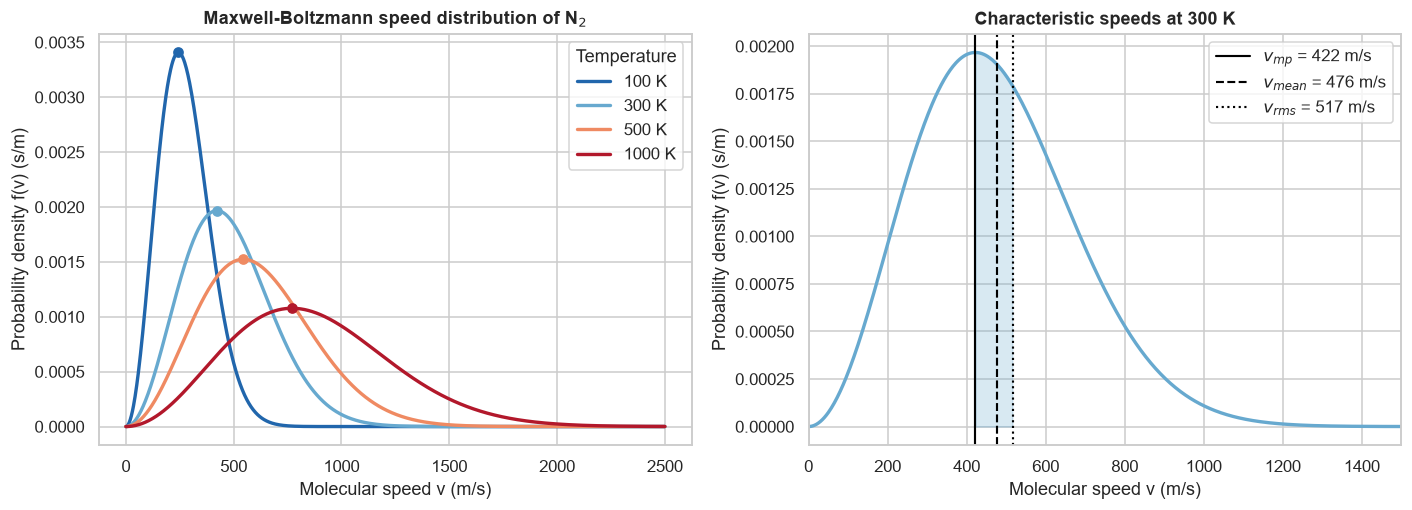

In [5]:
v = np.linspace(0, 2500, 1000)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# Left: the four temperatures
ax = axes[0]
for T in TEMPERATURES:
    ax.plot(v, maxwell_pdf(v, T), color=TEMP_COLORS[T], lw=2.2, label=f"{T} K")
    ax.plot(v_most_probable(T), maxwell_pdf(v_most_probable(T), T), "o",
            color=TEMP_COLORS[T], ms=6)
ax.set_title("Maxwell-Boltzmann speed distribution of N$_2$")
ax.set_xlabel("Molecular speed v (m/s)")
ax.set_ylabel("Probability density f(v) (s/m)")
ax.legend(title="Temperature")

# Right: the three characteristic speeds at 300 K
T0 = 300
ax = axes[1]
ax.plot(v, maxwell_pdf(v, T0), color=TEMP_COLORS[T0], lw=2.2)
speeds = {"$v_{mp}$": v_most_probable(T0), "$v_{mean}$": v_mean_theory(T0),
          "$v_{rms}$": v_rms_theory(T0)}
for (name, value), ls in zip(speeds.items(), ["-", "--", ":"]):
    ax.axvline(value, color="black", ls=ls, lw=1.4, label=f"{name} = {value:.0f} m/s")
ax.fill_between(v, maxwell_pdf(v, T0),
                where=(v >= speeds["$v_{mp}$"]) & (v <= speeds["$v_{rms}$"]),
                color=TEMP_COLORS[T0], alpha=0.25)
ax.set_xlim(0, 1500)
ax.set_title("Characteristic speeds at 300 K")
ax.set_xlabel("Molecular speed v (m/s)")
ax.set_ylabel("Probability density f(v) (s/m)")
ax.legend()

plt.tight_layout()
fig.savefig(f"{FIG_DIR}/fig_3_6_theoretical_distributions.png", bbox_inches="tight")
plt.show()

**Interpretation of the graphs**

*Left graph – effect of temperature.*
- **Shift:** the peak (dot) moves from about 244 m/s at 100 K to about 771 m/s at 1000 K. Hotter molecules move faster.
- **Flatten:** the 100 K curve is tall and narrow, while the 1000 K curve is low and wide. All curves have the same area (1), so a wider curve must be lower.
- **Asymmetry:** every curve rises quickly from zero and has a long tail on the right. The tail is longer at high temperature. Using the theoretical CDF, about **5.6 %** of the molecules move faster than 1,500 m/s at 1000 K, but only about 0.17 % at 500 K, and practically none at 100 K.
- **Overlap:** the curves overlap a lot, especially 300 K and 500 K. A molecule with a speed of 500 m/s could come from **any** of the four gases. This overlap is the physical reason why classifying the temperature from a single molecule is difficult (hypothesis H4, Section 9.2).

*Right graph – the three speeds at 300 K.*
The lines appear in the order $v_{mp}$ (422 m/s) < $v_{mean}$ (476 m/s) < $v_{rms}$ (517 m/s). The shaded area shows the gap between them. The gap between $v_{mp}$ and $v_{mean}$ exists because the distribution is right-skewed: for a symmetric distribution, the mode and the mean would be equal. $v_{rms}$ is always at least as large as $v_{mean}$, because squaring gives more weight to the fast molecules.

**Link to the next step.** We now know what the data *should* look like. In Section 4, we generate random molecular speeds from this distribution, and in Sections 6–7, we test whether the simulated data really agrees with these curves.

## 4. Data Generation and Dataset Description

*CRISP-DM phase 2: Data Generation.*

In this section we create the dataset of the project. We simulate the speeds of N₂ molecules at 100, 300, 500 and 1000 K, and we add physically meaningful variables. Finally, we check the data against the theory of Section 3 and save it as a CSV file.

### 4.1 Physical Constants and the Mass of N₂

We already defined the constants in Section 3.5.1, and we reuse them here:

| Python name | Quantity | Value |
|---|---|---|
| `K_B` | Boltzmann constant $k_B$ | $1.380649\times10^{-23}$ J/K (exact) |
| `N_A` | Avogadro constant $N_A$ | $6.02214076\times10^{23}$ mol⁻¹ (exact) |
| `M_N2` | Molar mass of N₂ | 0.0280134 kg/mol |
| `M_MOLECULE` | Mass of one N₂ molecule, $m = M/N_A$ | $4.6517\times10^{-26}$ kg |

**Why N₂?** Nitrogen makes up about 78 % of air. At these temperatures and at normal pressure, it behaves very close to an **ideal gas**, which is the assumption behind the Maxwell-Boltzmann distribution. We only simulate the **translational** motion (the motion of the centre of mass). N₂ can also rotate, but rotation does not change the speed distribution.

*Note on 100 K:* at normal pressure, nitrogen boils at about 77 K, so 100 K is still a gas, but it is closer to the point where real gases deviate from ideal behaviour. In the simulation, we treat all four temperatures as an ideal gas, and we note this in the Limitations (Section 14).

### 4.2 SciPy Maxwell Parameters

**A. What are we doing?**
We find the correct parameters for `scipy.stats.maxwell`, and we prove that SciPy's distribution is exactly the Maxwell-Boltzmann distribution of Section 3.2.

**B. Why are we doing it?**
SciPy uses a general, "unit-free" form of the distribution. If we pass the wrong parameter (for example, the temperature itself), SciPy will still produce numbers, but they will be physically wrong. This is a silent error, the most dangerous kind, so we check it.

**C. Mathematical foundation**
SciPy defines the standard Maxwell distribution as

$$f_{\text{SciPy}}(x) = \sqrt{\frac{2}{\pi}}\; x^2\, e^{-x^2/2}, \qquad x \ge 0$$

and with the parameters `loc` and `scale = a`, it uses $x = (v - \text{loc})/a$ and $f(v) = f_{\text{SciPy}}(x)/a$.

With `loc = 0`:

$$f(v) = \sqrt{\frac{2}{\pi}}\,\frac{v^2}{a^3}\, e^{-v^2/2a^2}$$

Now compare this with the physics formula. The exponent $-\dfrac{v^2}{2a^2}$ must be equal to $-\dfrac{mv^2}{2k_BT}$, so

$$a^2 = \frac{k_BT}{m} \quad\Rightarrow\quad \boxed{a = \sqrt{\frac{k_BT}{m}}}$$

Check the constant: with $a^2 = k_BT/m$, we get $\sqrt{2/\pi}\,/a^3 = 4\pi\left(\frac{m}{2\pi k_BT}\right)^{3/2}$, because $4\pi/(2\pi)^{3/2} = \sqrt{2/\pi}$. ✓

So:
- **`scale = a = √(k_B·T/m)`**. This is the standard deviation $\sigma$ of each velocity component (Section 3.1).
- **`loc = 0`**, because speeds start at 0. A non-zero `loc` would shift the whole distribution, which has no physical meaning here.

**D. Python explanation**
- `stats.maxwell(loc=0, scale=a)` creates a "frozen" distribution object with fixed parameters.
- `.mean()`, `.std()` and `.pdf(v)` return its mean, standard deviation and density.
- We compare these with our own physics functions from Section 3.5.

**E. Expected result**
The SciPy mean and standard deviation should be equal to $v_{mean}$ and $\sigma_v$, and the SciPy PDF should be equal to our `maxwell_pdf` at every speed, up to rounding errors.

In [6]:
def maxwell_scale(T, m=M_MOLECULE):
    # SciPy scale parameter a = sqrt(k_B T / m), in m/s
    return np.sqrt(K_B * T / m)

v_grid = np.linspace(0, 3000, 2001)
param_rows = []
for T in TEMPERATURES:
    a = maxwell_scale(T)
    dist = stats.maxwell(loc=0, scale=a)
    param_rows.append({
        "T (K)": T,
        "scale a (m/s)": a,
        "SciPy mean (m/s)": dist.mean(),
        "formula v_mean (m/s)": v_mean_theory(T),
        "SciPy std (m/s)": dist.std(),
        "formula sigma_v (m/s)": v_std_theory(T),
        "max |PDF difference|": np.max(np.abs(dist.pdf(v_grid) - maxwell_pdf(v_grid, T))),
    })

param_table = pd.DataFrame(param_rows).set_index("T (K)")
param_table.style.format({c: "{:.3f}" for c in param_table.columns[:-1]} | {"max |PDF difference|": "{:.2e}"})

,scale a (m/s),SciPy mean (m/s),formula v_mean (m/s),SciPy std (m/s),formula sigma_v (m/s),max |PDF difference|
T (K),,,,,,
100,172.280,274.919,274.919,116.020,116.020,2.17e-18
300,298.397,476.173,476.173,200.953,200.953,8.67e-19
500,385.229,614.737,614.737,259.429,259.429,8.67e-19
1000,544.796,869.369,869.369,366.887,366.887,7.59e-19


**Interpretation.** For all four temperatures, SciPy's mean and standard deviation are **identical** to our physics formulas (to 3 decimals). The largest difference between the two PDFs is below $3\times10^{-18}$ s/m, which is pure rounding error (the PDF values themselves are around $10^{-3}$). This proves that `stats.maxwell(loc=0, scale=√(k_B T/m))` **is** the Maxwell-Boltzmann distribution for N₂. The scale parameter grows from 172.3 m/s at 100 K to 544.8 m/s at 1000 K, again a factor of $\sqrt{10}$.

### 4.3 Sample Size and Random Seed

**A. What are we doing?**
We choose the number of simulated molecules per temperature, and we justify the choice with statistics.

**B. Why are we doing it?**
- If the sample is too small, the statistics (mean, skewness and so on) are noisy, and the results depend on luck.
- If the sample is too large, the notebook becomes slow (especially cross-validation in Section 10), and the statistical tests become extremely sensitive (Section 7.5).

We need a size that is "large enough" and that we can justify.

**C. Mathematical foundation**
The **standard error** of the sample mean (ML course, lesson 1.3.6) is

$$SE(\bar{v}) = \frac{\sigma_v}{\sqrt{n}}$$

It tells us how much the sample mean would change from one simulation to another. A 95 % confidence interval is about $\bar{v} \pm 1.96\,SE$. Because of the $\sqrt{n}$, we must use **4 times more data to make the error 2 times smaller**.

Higher moments, such as skewness and kurtosis, need more data than the mean. The standard error of the sample skewness is about $\sqrt{6/n}$, and that of the excess kurtosis is about $\sqrt{24/n}$ (these approximations are exact for normal data and a good guide here).

**D. Python explanation**
We calculate these standard errors for several values of $n$, at the widest temperature (1000 K), where the error is largest.

**E. Expected result**
A table showing that the errors become small when $n$ grows. We choose $n = 10{,}000$ if the relative error of the mean is well below 1 %.

In [7]:
N_PER_TEMPERATURE = 10_000     # our choice, justified by the table below

sigma_1000 = v_std_theory(1000)
mean_1000 = v_mean_theory(1000)
size_rows = []
for n in [100, 1_000, 10_000, 100_000]:
    se = sigma_1000 / np.sqrt(n)
    size_rows.append({
        "n per temperature": n,
        "SE of mean at 1000 K (m/s)": se,
        "95% CI half-width (m/s)": 1.96 * se,
        "relative SE of mean (%)": 100 * se / mean_1000,
        "SE of skewness": np.sqrt(6 / n),
        "SE of excess kurtosis": np.sqrt(24 / n),
    })
pd.DataFrame(size_rows).set_index("n per temperature").style.format("{:.3f}")

,SE of mean at 1000 K (m/s),95% CI half-width (m/s),relative SE of mean (%),SE of skewness,SE of excess kurtosis
n per temperature,,,,,
100,36.689,71.910,4.220,0.245,0.490
1000,11.602,22.740,1.335,0.077,0.155
10000,3.669,7.191,0.422,0.024,0.049
100000,1.160,2.274,0.133,0.008,0.015


**Interpretation.** With **n = 10,000 per temperature**, the standard error of the mean at 1000 K is only 3.7 m/s, which is **0.42 %** of the mean speed. The 95 % confidence interval is about ±7.2 m/s. The skewness and kurtosis are also estimated precisely (SE ≈ 0.024 and 0.049).

Going to 100,000 would reduce the errors by $\sqrt{10}\approx3.2$, but it would make the notebook 10 times slower, and the KS test would become sensitive to tiny numerical details (Section 7.5). With n = 1,000, the mean error would be 1.3 %, which is too large to show small physical differences clearly. So **10,000 is a good balance** between precision and speed.

### 4.4 Generating the Molecular Speeds

**A. What are we doing?**
We draw 10,000 random molecular speeds from the Maxwell-Boltzmann distribution at each of the four temperatures (40,000 molecules in total).

**B. Why are we doing it?**
This is the core dataset of the project (objective 1). Each row represents **one molecule** in a gas at a known temperature.

**C. Mathematical / physical foundation**
Each speed is an independent random draw $v_i \sim \text{Maxwell}(\text{scale} = \sqrt{k_BT/m})$. "Independent" means that one molecule's speed tells us nothing about another molecule's speed. This is true for an ideal gas in equilibrium.

**D. Python explanation**
- `rng_data = np.random.default_rng(SEED)` creates a **new** random generator with our seed, just for the data. Then the dataset is always identical, even if other cells that use random numbers are run before this one.
- `stats.maxwell.rvs(loc=0, scale=a, size=n, random_state=rng_data)` draws `n` random values ("rvs" means "random variates").
- We build one small DataFrame per temperature and join them with `pd.concat`. `ignore_index=True` gives the rows a new index from 0 to 39,999.

**E. Expected result**
A DataFrame with 40,000 rows: 10,000 per temperature. All speeds are positive. The typical speeds should be close to the theoretical values of Section 3.5.

In [8]:
rng_data = np.random.default_rng(SEED)

frames = []
for T in TEMPERATURES:
    speeds = stats.maxwell.rvs(loc=0, scale=maxwell_scale(T),
                               size=N_PER_TEMPERATURE, random_state=rng_data)
    frames.append(pd.DataFrame({"Temperature": T, "Speed": speeds}))

df = pd.concat(frames, ignore_index=True)

print(f"Rows: {len(df):,}")
print(df.groupby("Temperature")["Speed"].agg(["count", "min", "mean", "max"]).round(1))

Rows: 40,000
             count     min     mean        max
Temperature                                   
100          10000 13.4000 275.9000   799.4000
300          10000 15.3000 476.3000 1,434.7000
500          10000 29.8000 610.1000 2,041.4000
1000         10000 39.1000 870.3000 2,625.8000


**Interpretation.** We now have **40,000 molecules** (10,000 per temperature). All speeds are positive. The sample means (275.9, 476.3, 610.1 and 870.3 m/s) are close to the theoretical values (274.9, 476.2, 614.7 and 869.4 m/s). We test this properly in Section 4.7.

The **range** grows strongly with temperature: the fastest molecule at 100 K moves at 799 m/s, but at 1000 K the fastest moves at 2,626 m/s. This is the "flattening" of the distribution. The slowest molecules (13–39 m/s) are close to zero at every temperature, because the distribution always starts at $v = 0$.

### 4.5 Adding Physical Variables

**A. What are we doing?**
We add the physical variables listed in the project design: the molecular mass, the speed squared, the kinetic energy and the three theoretical speeds. We also add three helpful extra columns.

**B. Why are we doing it?**
- `Kinetic_Energy` and `Speed_Squared` connect the speed to energy and temperature (Section 3.4).
- The theoretical columns let us compare every molecule with the theory.
- `Normalised_Speed` $= v / v_{mp}(T)$ removes the effect of temperature. It lets us test a beautiful physics prediction: after normalisation, all four temperatures should follow **one universal curve** (Section 6.9).

**C. Physical foundation**

$$E_k = \tfrac{1}{2} m v^2, \qquad v^2 = v\cdot v, \qquad u = \frac{v}{v_{mp}(T)}$$

If we substitute $v = u\,v_{mp}$ into $f(v)$, the temperature disappears completely:

$$f(u) = \frac{4}{\sqrt{\pi}}\, u^2\, e^{-u^2}$$

This is why the normalised speed has the same distribution at every temperature.

⚠️ **Data leakage warning.** `Theoretical_Mean_Speed`, `Theoretical_RMS_Speed`, `Theoretical_Most_Probable_Speed` and `Normalised_Speed` are **calculated from the temperature**. If we gave them to a classifier, it could read the answer directly from these columns. That is **target leakage** (ML course, lesson 2.3). We keep them in the dataset for physics and validation, but we will **never** use them as model inputs. We store their names in the list `LEAKY_COLUMNS`, so later sections can remove them automatically.

**D. Python explanation**
- Operations on pandas columns are **vectorised**: `0.5 * df["Molecular_Mass"] * df["Speed"]**2` calculates all 40,000 energies at once, without a loop.
- `df["Temperature"].map(v_mean_theory)` applies the function to each temperature value.
- `Molecule_ID` gives every molecule a unique number. `Temperature_Label` is a readable text label such as "300 K", for graphs.
- We also convert the energy to meV in `Kinetic_Energy_meV`. Values like $6\times10^{-21}$ J are hard to read, while 39 meV is easy. It is the same information in a different unit.

**E. Expected result**
A DataFrame with 40,000 rows and 12 columns. At 300 K, a typical kinetic energy should be around $6\times10^{-21}$ J (about 39 meV).

In [9]:
df["Molecular_Mass"] = M_MOLECULE
df["Speed_Squared"] = df["Speed"] ** 2
df["Kinetic_Energy"] = 0.5 * df["Molecular_Mass"] * df["Speed"] ** 2          # J
df["Kinetic_Energy_meV"] = df["Kinetic_Energy"] / constants.e * 1000           # meV
df["Theoretical_Mean_Speed"] = df["Temperature"].map(v_mean_theory)
df["Theoretical_RMS_Speed"] = df["Temperature"].map(v_rms_theory)
df["Theoretical_Most_Probable_Speed"] = df["Temperature"].map(v_most_probable)
df["Normalised_Speed"] = df["Speed"] / df["Theoretical_Most_Probable_Speed"]
df["Temperature_Label"] = df["Temperature"].astype(str) + " K"
df.insert(0, "Molecule_ID", np.arange(1, len(df) + 1))

# Columns that are calculated from the temperature -> never use them as model inputs
LEAKY_COLUMNS = ["Theoretical_Mean_Speed", "Theoretical_RMS_Speed",
                 "Theoretical_Most_Probable_Speed", "Normalised_Speed"]

print(df.shape)
df.groupby("Temperature").head(2).sort_values("Temperature")

(40000, 12)


,Molecule_ID,Temperature,Speed,Molecular_Mass,Speed_Squared,Kinetic_Energy,Kinetic_Energy_meV,Theoretical_Mean_Speed,Theoretical_RMS_Speed,Theoretical_Most_Probable_Speed,Normalised_Speed,Temperature_Label
0,1,100,301.1418,4.6517e-26,"90,686.3766",2.1092e-21,13.1649,274.9187,298.3972,243.6403,1.2360,100 K
1,2,100,359.6864,4.6517e-26,"129,374.3330",3.0091e-21,18.7812,274.9187,298.3972,243.6403,1.4763,100 K
10000,10001,300,712.4738,4.6517e-26,"507,618.9849",1.1807e-20,73.6906,476.1731,516.8392,421.9974,1.6883,300 K
10001,10002,300,342.5186,4.6517e-26,"117,318.9990",2.7287e-21,17.0311,476.1731,516.8392,421.9974,0.8117,300 K
20000,20001,500,869.5389,4.6517e-26,"756,097.9742",1.7586e-20,109.7621,614.7368,667.2365,544.7963,1.5961,500 K
20001,20002,500,408.6895,4.6517e-26,"167,027.1439",3.8848e-21,24.2472,614.7368,667.2365,544.7963,0.7502,500 K
30000,30001,1000,761.0942,4.6517e-26,"579,264.3588",1.3473e-20,84.0914,869.3692,943.6149,770.4584,0.9878,1000 K
30001,30002,1000,584.2755,4.6517e-26,"341,377.8794",7.9400e-21,49.5576,869.3692,943.6149,770.4584,0.7583,1000 K


**Interpretation.** The dataset now has **12 columns**. For example, the first molecule at 100 K has $v = 301.1$ m/s, $v^2 = 90{,}686$ m²/s², $E_k = 2.11\times10^{-21}$ J $= 13.2$ meV, and a normalised speed $v/v_{mp} = 1.24$ (it moves 24 % faster than the most probable speed). The first molecule at 300 K has $E_k = 73.7$ meV, which is above the average 38.8 meV because it is a fast molecule (712 m/s).

The theoretical columns take the same value for all molecules at the same temperature, as expected.

### 4.6 Data Dictionary

| Variable | Description | Unit | Type | Role |
|---|---|---|---|---|
| `Molecule_ID` | Unique number of the simulated molecule | – | integer | identifier (not a feature) |
| `Temperature` | Temperature of the gas | K | integer (4 values) | **target** for classification; input for regression |
| `Molecular_Mass` | Mass of one N₂ molecule | kg | float (constant) | physical constant |
| `Speed` | Simulated molecular speed | m/s | float | **main measured variable** |
| `Speed_Squared` | Molecular speed squared | m²/s² | float | physics feature |
| `Kinetic_Energy` | Translational kinetic energy, $\tfrac12 mv^2$ | J | float | physics feature |
| `Kinetic_Energy_meV` | Same energy in milli-electronvolts | meV | float | readable copy of `Kinetic_Energy` |
| `Theoretical_Mean_Speed` | $\sqrt{8k_BT/\pi m}$ | m/s | float (4 values) | validation only ⚠️ leakage |
| `Theoretical_RMS_Speed` | $\sqrt{3k_BT/m}$ | m/s | float (4 values) | validation only ⚠️ leakage |
| `Theoretical_Most_Probable_Speed` | $\sqrt{2k_BT/m}$ | m/s | float (4 values) | validation only ⚠️ leakage |
| `Normalised_Speed` | $v / v_{mp}(T)$, no unit | – | float | physics only ⚠️ leakage |
| `Temperature_Label` | Text label, e.g. "300 K" | – | text | labels for graphs |

**Note on redundancy.** `Speed`, `Speed_Squared`, `Kinetic_Energy` and `Kinetic_Energy_meV` are all exact functions of each other, because the mass is constant. They describe **one** piece of information in different units. We study what this means for Machine Learning in Section 8.1.

### 4.7 First Validation Against Theory

#### 4.7.1 Sample statistics versus theoretical values

**A. What are we doing?**
We compare the statistics of the simulated data with the theoretical values: mean speed, RMS speed, standard deviation and mean kinetic energy.

**B. Why are we doing it?**
This is the "simulated data does not match theory" risk from my proposal. Before any analysis, we must be sure that the data generator works correctly.

**C. Statistical foundation**
A sample mean is never *exactly* equal to the true mean, because of random sampling. The question is whether the difference is **small compared with the expected random error**. We use the **z-score**:

$$z = \frac{\bar{v} - v_{mean}}{\sigma_v/\sqrt{n}}$$

If the generator is correct, $z$ behaves like a standard normal variable (CLT). So we expect $|z| < 2$ in about 95 % of cases. A value like $|z| > 3$ would point to a problem.

For the kinetic energy, we check the ratio $\langle E_k\rangle_{\text{sample}} / \left(\tfrac{3}{2}k_BT\right)$, which should be close to 1.

**D. Python explanation**
- `groupby("Temperature")` splits the data into the four gases.
- `np.sqrt(np.mean(v**2))` is the sample RMS speed.
- `.std(ddof=1)` uses Bessel's correction ($n-1$), as in lesson 1.3.1.

**E. Expected result**
Relative errors well below 1 %, all $|z|$ values small (about 2 or less), and energy ratios very close to 1.

In [10]:
val_rows = []
for T, g in df.groupby("Temperature"):
    v_s = g["Speed"].to_numpy()
    n = len(v_s)
    mean_s, rms_s, std_s = v_s.mean(), np.sqrt(np.mean(v_s**2)), v_s.std(ddof=1)
    val_rows.append({
        "T (K)": T,
        "mean: sample": mean_s,
        "mean: theory": v_mean_theory(T),
        "mean: rel. error (%)": 100 * (mean_s - v_mean_theory(T)) / v_mean_theory(T),
        "z-score of mean": (mean_s - v_mean_theory(T)) / (v_std_theory(T) / np.sqrt(n)),
        "RMS: sample": rms_s,
        "RMS: theory": v_rms_theory(T),
        "std: sample": std_s,
        "std: theory": v_std_theory(T),
        "<E_k> / (1.5 k_B T)": g["Kinetic_Energy"].mean() / mean_kinetic_energy(T),
    })

validation = pd.DataFrame(val_rows).set_index("T (K)")
validation.columns = [c.replace("<E_k>", "mean E_k") for c in validation.columns]
fmt = {c: "{:.2f}" for c in validation.columns}
fmt.update({"mean: rel. error (%)": "{:+.3f}", "z-score of mean": "{:+.2f}",
            "mean E_k / (1.5 k_B T)": "{:.4f}"})
validation.style.format(fmt)

,mean: sample,mean: theory,mean: rel. error (%),z-score of mean,RMS: sample,RMS: theory,std: sample,std: theory,mean E_k / (1.5 k_B T)
T (K),,,,,,,,,
100,275.93,274.92,+0.369,+0.88,299.47,298.40,116.39,116.02,1.0072
300,476.26,476.17,+0.019,+0.04,518.15,516.84,204.11,200.95,1.0051
500,610.12,614.74,-0.750,-1.78,661.87,667.24,256.58,259.43,0.9840
1000,870.34,869.37,+0.112,+0.26,945.99,943.61,370.70,366.89,1.0050


**Interpretation.** The simulated data agrees with the theory:

- **Mean speed:** all relative errors are below 1 % (from −0.75 % to +0.37 %). All **z-scores are between −2 and +2** (the largest is −1.78 at 500 K). So the differences are of the size we expect from random sampling alone. They are not a sign of an error in the generator.
- **RMS speed and standard deviation** are also close to theory. The largest difference is the standard deviation at 300 K (204.1 vs 201.0 m/s). Its standard error is about 1.5 m/s here, so this difference is about 2.2 standard errors: a little large, but still possible by chance when we look at many numbers at the same time. The KS tests in Section 7.3 will check the full distribution more rigorously.
- **Kinetic energy:** the ratio $\langle E_k\rangle / \tfrac32 k_BT$ is between 0.984 and 1.007, so the **equipartition result $\langle E_k\rangle = \tfrac32k_BT$ is confirmed** within about 1.6 %.

Notice that the 500 K sample is a little "slow" in *all* columns (mean, RMS, std and energy). This makes sense: these statistics are calculated from the same 10,000 molecules, so one random fluctuation affects all of them in the same direction.

#### 4.7.2 Independent check: building speeds from three normal velocity components

**A. What are we doing?**
We create speeds with a **completely different method**, based on the physics of Section 3.1. We draw three normal velocity components $v_x, v_y, v_z$ and calculate $v = \sqrt{v_x^2+v_y^2+v_z^2}$. Then we compare these speeds with the SciPy speeds.

**B. Why are we doing it?**
If the derivation in Section 3.1 is right, both methods must give the **same distribution**. This confirms two things at once: that SciPy's `maxwell` is the correct tool, and that "three normal components → Maxwell speed" is true.

**C. Mathematical foundation**
Each component: $v_x, v_y, v_z \sim N\!\left(0,\; \sigma^2 = k_BT/m\right)$. The speed is the Euclidean norm of the velocity vector (ML course, lesson 1.1.1, vector norms).

We compare the two samples with the **two-sample Kolmogorov-Smirnov test**. It measures the largest vertical distance between two empirical CDFs. A large p-value means "no evidence that the two samples come from different distributions". The KS test is explained in detail in Section 7.3.

**D. Python explanation**
- `rng_check.normal(0, sigma, size=(n, 3))` creates an $n \times 3$ matrix: one row per molecule and one column per direction.
- `np.linalg.norm(..., axis=1)` calculates the length of each row vector.
- `stats.ks_2samp(a, b)` performs the two-sample KS test.
- We use a **different** seed (`SEED + 1`), so this check is independent of the main dataset.

**E. Expected result**
For each temperature: very similar means, and a KS p-value that is not small (typically above 0.05).

In [11]:
rng_check = np.random.default_rng(SEED + 1)

comp_rows = []
for T, g in df.groupby("Temperature"):
    sigma = maxwell_scale(T)                                    # std of each component
    velocity = rng_check.normal(0, sigma, size=(N_PER_TEMPERATURE, 3))
    speed_from_components = np.linalg.norm(velocity, axis=1)
    ks = stats.ks_2samp(g["Speed"], speed_from_components)
    comp_rows.append({
        "T (K)": T,
        "mean, SciPy maxwell (m/s)": g["Speed"].mean(),
        "mean, 3 normal components (m/s)": speed_from_components.mean(),
        "KS statistic D": ks.statistic,
        "KS p-value": ks.pvalue,
    })

pd.DataFrame(comp_rows).set_index("T (K)").style.format(
    {"mean, SciPy maxwell (m/s)": "{:.1f}", "mean, 3 normal components (m/s)": "{:.1f}",
     "KS statistic D": "{:.4f}", "KS p-value": "{:.3f}"})

,"mean, SciPy maxwell (m/s)","mean, 3 normal components (m/s)",KS statistic D,KS p-value
T (K),,,,
100,275.9,275.6,0.0090,0.813
300,476.3,474.2,0.0191,0.052
500,610.1,610.1,0.0122,0.446
1000,870.3,867.0,0.0104,0.652


**Interpretation.** The two methods give **the same distribution**. The means agree within about 0.5 %, and the KS distances are very small (D ≤ 0.019). All four p-values are above 0.05, so there is **no evidence** that the two methods produce different distributions. This confirms the derivation of Section 3.1: three independent normal velocity components produce exactly the Maxwell-Boltzmann speed distribution.

The p-value at 300 K (0.052) is close to 0.05. This is not a problem. When the null hypothesis is true, p-values are **uniformly distributed** between 0 and 1, so in four tests, one p-value near 0.05 is quite normal. We discuss this "multiple testing" idea again in Section 7.5.

### 4.8 Saving the Dataset

**A. What are we doing?**
We save the complete dataset as a CSV file in a `data/` folder.

**B. Why are we doing it?**
- The proposal requires a dataset file as part of the project.
- Other people (or the final report) can use exactly the same data without running the simulation again.
- In Section 5, we **load the data back from the CSV**, like a real data pipeline. This also checks that the file was saved correctly.

**D. Python explanation**
- `os.makedirs("data", exist_ok=True)` creates the folder if it does not exist.
- `df.to_csv(path, index=False)` writes the table without the pandas index. The index is just a row number, and we already have `Molecule_ID`.
- `os.path.getsize` returns the file size in bytes.

**E. Expected result**
A file `data/maxwell_boltzmann_n2_dataset.csv` with 40,000 rows and 12 columns.

In [12]:
DATA_DIR = "data"
os.makedirs(DATA_DIR, exist_ok=True)
DATA_PATH = os.path.join(DATA_DIR, "maxwell_boltzmann_n2_dataset.csv")

df.to_csv(DATA_PATH, index=False)
print(f"Saved {len(df):,} rows x {df.shape[1]} columns to {DATA_PATH}")
print(f"File size: {os.path.getsize(DATA_PATH) / 1e6:.1f} MB")

Saved 40,000 rows x 12 columns to data\maxwell_boltzmann_n2_dataset.csv
File size: 7.6 MB


**Result.** The dataset was saved as `data/maxwell_boltzmann_n2_dataset.csv` (40,000 rows × 12 columns, about 7.6 MB). Objective 1 of the proposal is complete.

## 5. Data Cleaning and Preparation

*CRISP-DM phase 3: Data Preparation.*

Our data is simulated, so we do not expect the usual problems of real data (missing values, typing errors, wrong units). But a professional pipeline **checks** data quality and does not assume it. The checks below also protect us against programming mistakes in Section 4.

We start by **loading the dataset from the CSV file**, so the rest of the notebook works on the saved file, exactly like a real project.

### 5.1 Shape and Data Types

**A. What are we doing?**
We load the CSV file and look at the size of the table and the data type of each column.

**B. Why are we doing it?**
- Loading from the file proves that the saved file is complete and readable.
- Wrong data types are a common source of errors. For example, a number stored as text cannot be used in calculations.

**D. Python explanation**
- `pd.read_csv(DATA_PATH)` reads the file into a DataFrame.
- `.shape` gives (rows, columns).
- `.info()` lists each column with its type and the number of non-missing values. `int64` means integer, `float64` means a decimal number, and `str` (or `object`) means text.
- `pd.testing.assert_frame_equal(...)` checks that the loaded table is identical to the table in memory. `check_exact=False` allows tiny rounding differences that can appear when decimal numbers are written to text and read back.

**E. Expected result**
40,000 rows and 12 columns. `Temperature` and `Molecule_ID` should be integers, `Temperature_Label` text, and all other columns floats.

In [13]:
data = pd.read_csv(DATA_PATH)

# The file must contain exactly what we saved
pd.testing.assert_frame_equal(data, df, check_exact=False, check_dtype=False)

print("Shape:", data.shape)
print()
data.info()

Shape: (40000, 12)

<class 'pandas.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 12 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Molecule_ID                      40000 non-null  int64  
 1   Temperature                      40000 non-null  int64  
 2   Speed                            40000 non-null  float64
 3   Molecular_Mass                   40000 non-null  float64
 4   Speed_Squared                    40000 non-null  float64
 5   Kinetic_Energy                   40000 non-null  float64
 6   Kinetic_Energy_meV               40000 non-null  float64
 7   Theoretical_Mean_Speed           40000 non-null  float64
 8   Theoretical_RMS_Speed            40000 non-null  float64
 9   Theoretical_Most_Probable_Speed  40000 non-null  float64
 10  Normalised_Speed                 40000 non-null  float64
 11  Temperature_Label                40000 non-null  str    
dtypes: float6

**Interpretation.** The file was read back correctly: `assert_frame_equal` found no difference from the data in memory. The table has **40,000 rows and 12 columns**. The types are correct: `Molecule_ID` and `Temperature` are integers, the physical variables are `float64`, and `Temperature_Label` is text. Every column has 40,000 non-null values.

### 5.2 Missing Values

**A. What are we doing?** We count the missing values (NaN) in every column.

**B. Why are we doing it?** Most scikit-learn models cannot work with missing values. In real data we would have to remove or impute them. In simulated data, a missing value would point to a bug, for example a calculation that failed.

**D. Python explanation** `data.isnull()` returns True for each missing cell, and `.sum()` counts the True values per column.

**E. Expected result** Zero missing values in all columns.

In [14]:
missing = data.isnull().sum()
print(missing)
print(f"\nTotal missing values: {missing.sum()}")

Molecule_ID                        0
Temperature                        0
Speed                              0
Molecular_Mass                     0
Speed_Squared                      0
Kinetic_Energy                     0
Kinetic_Energy_meV                 0
Theoretical_Mean_Speed             0
Theoretical_RMS_Speed              0
Theoretical_Most_Probable_Speed    0
Normalised_Speed                   0
Temperature_Label                  0
dtype: int64

Total missing values: 0


**Interpretation.** There are **no missing values** in any column. No imputation is needed.

### 5.3 Duplicate Observations

**A. What are we doing?** We look for rows that appear more than once, and for repeated speed values.

**B. Why are we doing it?** Duplicate rows can give some observations too much weight. They can also cause **leakage**: if the same row is in both the training set and the test set, the model is tested on data it has already seen (ML course, lesson 2.3).

**C. Mathematical foundation** The speed is a **continuous** random variable. For a continuous variable, the probability that two independent draws are exactly equal is zero. With 64-bit numbers, repeated values are practically impossible. Of course, the theoretical columns contain only 4 different values each, by design. That is not duplication of observations.

**D. Python explanation**
- `data.duplicated().sum()` counts rows that are complete copies of an earlier row.
- We also check duplicates **without** `Molecule_ID`, because the ID is unique by construction and would hide real duplicates.
- `data["Speed"].duplicated().sum()` counts repeated speed values.

**E. Expected result** Zero duplicate rows, and zero repeated speeds.

In [15]:
print("Duplicate rows (all columns):           ", data.duplicated().sum())
print("Duplicate rows (ignoring Molecule_ID):  ", data.drop(columns="Molecule_ID").duplicated().sum())
print("Repeated speed values:                  ", data["Speed"].duplicated().sum())
print("Unique values in Theoretical_Mean_Speed:", data["Theoretical_Mean_Speed"].nunique())

Duplicate rows (all columns):            0
Duplicate rows (ignoring Molecule_ID):   0
Repeated speed values:                   0
Unique values in Theoretical_Mean_Speed: 4


**Interpretation.** There are **no duplicate rows** and **no repeated speed values** among the 40,000 molecules, as expected for a continuous variable. The theoretical columns have exactly 4 unique values each (one per temperature), which is correct by design. So the train/test splits in Section 9 cannot leak information through duplicated rows.

### 5.4 Physical Consistency Checks

**A. What are we doing?**
We check that the data obeys the physics. Every speed must be positive and finite, the energy must be equal to $\tfrac12 mv^2$, the mass must be constant, and there must be 10,000 molecules per temperature.

**B. Why are we doing it?**
A dataset can be "clean" in the statistical sense (no missing values, no duplicates) and still be **physically wrong**. Domain knowledge is an essential part of data cleaning. Here, the domain is physics.

**C. Physical foundation**
- $v \ge 0$, because a speed is the length of a vector.
- $E_k = \tfrac{1}{2}mv^2 > 0$, and the energy must agree with the speed.
- Even the fastest molecule cannot reach the speed of light, so classical (non-relativistic) mechanics is valid. We check the ratio $v_{max}/c$.

**D. Python explanation**
- `assert condition, "message"` stops the notebook with an error if the condition is False. This is a simple and strong way to test data.
- `np.isfinite` is False for NaN and for infinity.
- `np.allclose(a, b, rtol=1e-9)` compares two arrays with a small relative tolerance, because decimal numbers are not stored exactly.
- `constants.c` is the speed of light.

**E. Expected result**
All checks pass (no `AssertionError`), and $v_{max}/c$ is extremely small.

In [16]:
assert np.isfinite(data.select_dtypes("number")).all().all(), "Non-finite values found"
assert (data["Speed"] > 0).all(), "Speeds must be positive"
assert np.allclose(data["Kinetic_Energy"], 0.5 * M_MOLECULE * data["Speed"] ** 2, rtol=1e-9), "E_k != 1/2 m v^2"
assert np.allclose(data["Speed_Squared"], data["Speed"] ** 2, rtol=1e-9), "Speed_Squared wrong"
assert data["Molecular_Mass"].nunique() == 1, "Mass must be constant"
assert (data["Temperature"].value_counts() == N_PER_TEMPERATURE).all(), "Unbalanced temperatures"
assert set(data["Temperature"]) == set(TEMPERATURES), "Unexpected temperature values"

print("All physical checks passed.")
print(f"Fastest molecule: {data['Speed'].max():.1f} m/s  ->  v_max / c = {data['Speed'].max() / constants.c:.2e}")
print(f"Slowest molecule: {data['Speed'].min():.2f} m/s")
print("\nMolecules per temperature:")
print(data["Temperature"].value_counts().sort_index())

All physical checks passed.
Fastest molecule: 2625.8 m/s  ->  v_max / c = 8.76e-06
Slowest molecule: 13.43 m/s

Molecules per temperature:
Temperature
100     10000
300     10000
500     10000
1000    10000
Name: count, dtype: int64


**Interpretation.** All physical checks passed. Every speed is positive and finite, the energy is exactly $\tfrac12mv^2$, the mass is constant, and the four classes are perfectly balanced (10,000 each).

The fastest molecule moves at 2,626 m/s, which is only $8.8\times10^{-6}$ of the speed of light. So **classical mechanics is fully valid**, and the relativistic correction (of order $(v/c)^2 \approx 10^{-10}$) is completely negligible.

#### 5.4.1 Outliers: should we remove the fast molecules?

**A. What are we doing?**
We apply the common **IQR rule** (ML course, lesson 1.3.1) to find "outliers" in the speed at each temperature. Then we decide what to do with them.

**B. Why are we doing it?**
In many data projects, outliers are removed. But an outlier is not always an error. Here we must decide whether the very fast molecules are errors or real physics.

**C. Statistical foundation**
The IQR rule marks a value as an outlier if it lies outside the interval

$$[\,Q_1 - 1.5\cdot IQR,\;\; Q_3 + 1.5\cdot IQR\,], \qquad IQR = Q_3 - Q_1$$

This rule was designed for roughly **symmetric** data. The Maxwell-Boltzmann distribution is **right-skewed** (Section 3.2), so it naturally has a long tail of high values, and the rule will flag many fast molecules. We can also calculate the **theoretical** fraction of molecules above the upper fence with the survival function $P(v > x) = 1 - F(x)$.

**D. Python explanation**
- `.quantile([0.25, 0.75])` gives $Q_1$ and $Q_3$.
- `stats.maxwell(scale=a).sf(x)` is the survival function $1 - F(x)$: the theoretical probability of a speed above $x$.

**E. Expected result**
A small percentage of molecules above the upper fence, and almost the same percentage predicted by the theory. Then these "outliers" are a real property of the distribution, not errors.

In [17]:
out_rows = []
for T, g in data.groupby("Temperature"):
    q1, q3 = g["Speed"].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    out_rows.append({
        "T (K)": T,
        "upper fence (m/s)": high,
        "below lower fence": int((g["Speed"] < low).sum()),
        "above upper fence": int((g["Speed"] > high).sum()),
        "% above (data)": 100 * (g["Speed"] > high).mean(),
        "% above (theory)": 100 * stats.maxwell(scale=maxwell_scale(T)).sf(high),
    })
pd.DataFrame(out_rows).set_index("T (K)").style.format(
    {"upper fence (m/s)": "{:.1f}", "% above (data)": "{:.2f}", "% above (theory)": "{:.2f}"})

,upper fence (m/s),below lower fence,above upper fence,% above (data),% above (theory)
T (K),,,,,
100,586.9,0,90,0.90,0.89
300,1026.4,0,86,0.86,0.80
500,1302.8,0,76,0.76,0.96
1000,1869.4,0,107,1.07,0.82


**Interpretation and decision.** The IQR rule finds **no low outliers** (the distribution starts at 0, so the lower fence is negative), and about **0.8–1.1 % high "outliers"** at each temperature. The theory predicts almost the same percentages (0.8–1.0 %). So these molecules are **not errors**. They are the real right tail of the Maxwell-Boltzmann distribution, the fast molecules that physics predicts.

**Decision: we keep all molecules.** Removing them would make the distribution artificially symmetric, reduce the mean, RMS and energy, and destroy exactly the physical feature (the tail) that makes the distribution special. This is an important lesson: the IQR rule assumes roughly symmetric data, and **domain knowledge must decide** whether an outlier is an error or a real phenomenon. When we need a scaler that is not sensitive to the tail, we can use `RobustScaler` (Dr. Iqbal, Week 7) instead of removing data.

### 5.5 Encoding the Temperature Label and Defining Feature Groups

**A. What are we doing?**
We prepare the target variable for Machine Learning, and we define, once and for all, which columns can be used as features.

**B. Why are we doing it?**
- For **classification**, the temperature is a **class label** with 4 categories. For **regression**, it is a **number**. We need both views of the same column.
- Writing the allowed feature lists in **one place** protects the whole project against target leakage. Every model later uses these lists.

**C. Explanation of the encoding**
The four temperatures are categories that have a natural order (100 < 300 < 500 < 1000 K). scikit-learn classifiers accept integer labels directly. We use the class codes 0, 1, 2, 3 in increasing temperature, and we keep a dictionary to translate back.

We do **not** use one-hot encoding for the target, because scikit-learn handles multi-class targets by itself. One-hot encoding is used for categorical **input** features, and we have none (ML course, lesson 8.2).

**D. Python explanation**
- `{T: i for i, T in enumerate(TEMPERATURES)}` builds the mapping `{100: 0, 300: 1, 500: 2, 1000: 3}`.
- `.map(...)` applies it to every row.
- The feature lists exclude the identifier, the constant mass, the text label and all leaky columns.

**E. Expected result**
A new column `Temperature_Class` with 10,000 rows in each class, and the feature lists printed below.

In [18]:
CLASS_OF_T = {T: i for i, T in enumerate(TEMPERATURES)}     # {100: 0, 300: 1, 500: 2, 1000: 3}
T_OF_CLASS = {i: T for T, i in CLASS_OF_T.items()}
data["Temperature_Class"] = data["Temperature"].map(CLASS_OF_T)

# Molecule-level features that are allowed for Machine Learning (no leakage)
MOLECULE_FEATURES = ["Speed", "Speed_Squared", "Kinetic_Energy"]
# Columns that must never be model inputs
EXCLUDED_COLUMNS = ["Molecule_ID", "Molecular_Mass", "Temperature_Label",
                    "Kinetic_Energy_meV"] + LEAKY_COLUMNS
TARGET_CLASS = "Temperature_Class"

assert not set(MOLECULE_FEATURES) & set(EXCLUDED_COLUMNS)
print("Class mapping:", CLASS_OF_T)
print("Rows per class:", data[TARGET_CLASS].value_counts().sort_index().to_dict())
print("Allowed molecule-level features:", MOLECULE_FEATURES)
print("Excluded from models:", EXCLUDED_COLUMNS)

Class mapping: {100: 0, 300: 1, 500: 2, 1000: 3}
Rows per class: {0: 10000, 1: 10000, 2: 10000, 3: 10000}
Allowed molecule-level features: ['Speed', 'Speed_Squared', 'Kinetic_Energy']
Excluded from models: ['Molecule_ID', 'Molecular_Mass', 'Temperature_Label', 'Kinetic_Energy_meV', 'Theoretical_Mean_Speed', 'Theoretical_RMS_Speed', 'Theoretical_Most_Probable_Speed', 'Normalised_Speed']


**Interpretation.** The target `Temperature_Class` has four perfectly balanced classes (10,000 each). Because the classes are balanced, **accuracy** is a fair metric, and a model that guesses randomly would get 25 %. This is the baseline that every classifier must beat.

The allowed molecule-level features are `Speed`, `Speed_Squared` and `Kinetic_Energy`. All columns that contain the answer (the theoretical speeds and the normalised speed) are excluded, so the models cannot "cheat". The sample-level features of RQ1 (Level B) are built in Section 8.3.

**The data is now clean and ready for exploratory analysis (Section 6).**

## 6. Exploratory Data Analysis (EDA)

*CRISP-DM phase 4: Exploratory Data Analysis.*

Objective 2 of the proposal is to **show how the distributions shift and flatten as the temperature increases**. In this section we describe the data with numbers (6.1) and with graphs (6.2–6.10). For every graph, we explain why we use it, the mathematics behind it, and what it tells us about the physics.

All graphs use the same colours: <span style="color:#2166ac">■ 100 K</span>, <span style="color:#67a9cf">■ 300 K</span>, <span style="color:#ef8a62">■ 500 K</span>, <span style="color:#b2182b">■ 1000 K</span>.

### 6.1 Descriptive Statistics per Temperature

**A. What are we doing?**
We calculate the main descriptive statistics of the speed for each temperature, and we compare the **shape** statistics (skewness, kurtosis) with their theoretical values.

**B. Why are we doing it?**
Descriptive statistics are the first numerical summary of a distribution. They show **where** the distribution is (location), **how wide** it is (spread) and **what shape** it has.

**C. Mathematical foundation** (ML course, lesson 1.3.1)

| Statistic | Formula | What it measures |
|---|---|---|
| Mean | $\bar{v} = \frac{1}{n}\sum v_i$ | location (centre of mass of the data) |
| Median | middle value of the sorted data | location, robust to the tail |
| Variance | $s^2 = \frac{1}{n-1}\sum (v_i-\bar{v})^2$ | spread, in (m/s)² |
| Standard deviation | $s = \sqrt{s^2}$ | spread, in m/s |
| Coefficient of variation | $CV = s/\bar{v}$ | spread **relative** to the mean (no unit) |
| Skewness | $g_1 = \frac{1}{n}\sum\left(\frac{v_i-\bar{v}}{s}\right)^3$ | asymmetry: > 0 means a long right tail |
| Excess kurtosis | $g_2 = \frac{1}{n}\sum\left(\frac{v_i-\bar{v}}{s}\right)^4 - 3$ | heaviness of the tails compared with a normal distribution (0 for a normal) |

**An important theoretical prediction.** The temperature only changes the **scale** $a = \sqrt{k_BT/m}$ of the distribution. It does not change its **shape**. Skewness, kurtosis and CV are calculated from $(v-\bar{v})/s$, so the scale cancels out. Therefore, theory predicts that these three numbers are **the same at every temperature**:

$$g_1 = \frac{2\sqrt{2}\,(16-5\pi)}{(3\pi-8)^{3/2}} \approx 0.486, \qquad g_2 = \frac{4(-96+40\pi-3\pi^2)}{(3\pi-8)^2} \approx 0.108, \qquad CV = \sqrt{\frac{3\pi}{8}-1} \approx 0.422$$

This prediction is very important for Machine Learning: if skewness and kurtosis do not depend on $T$, they cannot help a model to find $T$ (Section 8).

**D. Python explanation**
- `groupby("Temperature")["Speed"].agg([...])` calculates several statistics per group in one step.
- `stats.skew` and `stats.kurtosis` (with the default `fisher=True`) give the skewness and the **excess** kurtosis.
- `stats.maxwell.stats(moments="sk")` returns the theoretical skewness and excess kurtosis of the Maxwell distribution.

**E. Expected result**
Mean, median, standard deviation and variance should grow with $T$. Skewness should be close to 0.486, kurtosis close to 0.108 and CV close to 0.422, **at all four temperatures**. Also, mean > median, because of the right tail.

In [19]:
desc = data.groupby("Temperature")["Speed"].agg(
    count="count", mean="mean", median="median", std="std", var="var", min="min", max="max")
desc["CV"] = desc["std"] / desc["mean"]
desc["skewness"] = data.groupby("Temperature")["Speed"].apply(stats.skew)
desc["excess kurtosis"] = data.groupby("Temperature")["Speed"].apply(stats.kurtosis)
desc["mean - median"] = desc["mean"] - desc["median"]

skew_th, kurt_th = (float(x) for x in stats.maxwell.stats(moments="sk"))
cv_th = np.sqrt(3 * np.pi / 8 - 1)
print(f"Theory (all temperatures): skewness = {skew_th:.4f}, excess kurtosis = {kurt_th:.4f}, CV = {cv_th:.4f}")

desc.style.format({"count": "{:,.0f}", "mean": "{:.1f}", "median": "{:.1f}", "std": "{:.1f}",
                   "var": "{:,.0f}", "min": "{:.1f}", "max": "{:.1f}", "CV": "{:.4f}",
                   "skewness": "{:.4f}", "excess kurtosis": "{:.4f}", "mean - median": "{:.1f}"})

Theory (all temperatures): skewness = 0.4857, excess kurtosis = 0.1082, CV = 0.4220


,count,mean,median,std,var,min,max,CV,skewness,excess kurtosis,mean - median
Temperature,,,,,,,,,,,
100,"10,000",275.9,265.6,116.4,"13,547",13.4,799.4,0.4218,0.4937,0.0987,10.3
300,"10,000",476.3,460.3,204.1,"41,660",15.3,1434.7,0.4286,0.4581,0.0404,16.0
500,"10,000",610.1,587.3,256.6,"65,834",29.8,2041.4,0.4205,0.5216,0.2414,22.8
1000,"10,000",870.3,834.7,370.7,"137,422",39.1,2625.8,0.4259,0.5096,0.1878,35.6


**Interpretation.** 1. **Location and spread grow with temperature.** The mean grows from 275.9 to 870.3 m/s and the standard deviation from 116.4 to 370.7 m/s, both by about $\sqrt{10} \approx 3.2$. The variance grows by about 10 (from 13,547 to 137,422 m²/s²), because variance is $\sigma^2 \propto T$. This is the "shift and flatten" of objective 2, shown with numbers.
2. **The mean is always larger than the median** (by 10.3 m/s at 100 K, up to 35.6 m/s at 1000 K). This is the typical sign of a **right-skewed** distribution: the few very fast molecules pull the mean up, but they hardly move the median. The gap grows with $T$ because the whole distribution is stretched.
3. **CV, skewness and kurtosis do not depend on temperature.** They only fluctuate around the theoretical values:
   - CV: 0.421–0.429 (theory 0.422)
   - skewness: 0.458–0.522 (theory 0.486)
   - excess kurtosis: 0.040–0.241 (theory 0.108)

   This confirms the prediction: temperature only changes the **scale** of the distribution, not its **shape**.

**Consequence for Machine Learning.** Skewness and kurtosis describe the shape, and the shape is the same at every temperature. So these two statistics **carry no information about $T$**. In the sample-level classification (Section 8.3), we expect the useful features to be the location and spread statistics (mean, median, standard deviation, percentiles), and skewness and kurtosis to be almost useless. We will test this with feature importance.

**A note on precision.** The kurtosis values vary much more than the skewness values. Higher-order statistics use the 4th power of the deviations, so a few tail molecules have a large effect, and they need much more data to be estimated precisely. The value at 500 K (0.241) is about 2.7 standard errors above theory (SE ≈ 0.049, Section 4.3). This is unusual, but it is one number among many that we have calculated. The formal distribution tests in Section 7 will check whether the 500 K sample really deviates from the Maxwell distribution.

### 6.2 Histograms with the Theoretical PDF

**A. What are we doing?**
We draw a histogram of the simulated speeds at each temperature, and on top of it the theoretical Maxwell-Boltzmann curve $f(v)$.

**B. Why are we doing it?**
A histogram is the most direct picture of a distribution. Putting the theoretical curve on top is a **visual goodness-of-fit test**: if the simulation is correct, the bars should follow the curve.

**C. Mathematical foundation**
A histogram divides the speed axis into bins of width $\Delta v$ and counts the molecules $n_j$ in each bin. To compare it with a PDF, we use the **density** scale:

$$\text{height}_j = \frac{n_j}{n\,\Delta v}$$

Then the total area of the bars is 1, like the area under $f(v)$. Because of random sampling, each bar fluctuates around the curve by about $\sqrt{n_j}$ molecules (Poisson noise), so small differences are normal.

**D. Python explanation**
- `plt.subplots(2, 2, sharex=True)` creates four graphs with the same x-axis, so the shift is easy to see.
- `ax.hist(..., bins=bins, density=True)` draws the histogram on the density scale.
- We use the same bin edges for all temperatures (`np.linspace(0, 2700, 91)`, so $\Delta v = 30$ m/s), so the four graphs are directly comparable.
- The vertical dashed line marks the theoretical mean speed.

**E. Expected result**
The bars should follow the theoretical curves closely. From 100 K to 1000 K, the histograms should move to the right and become wider and lower.

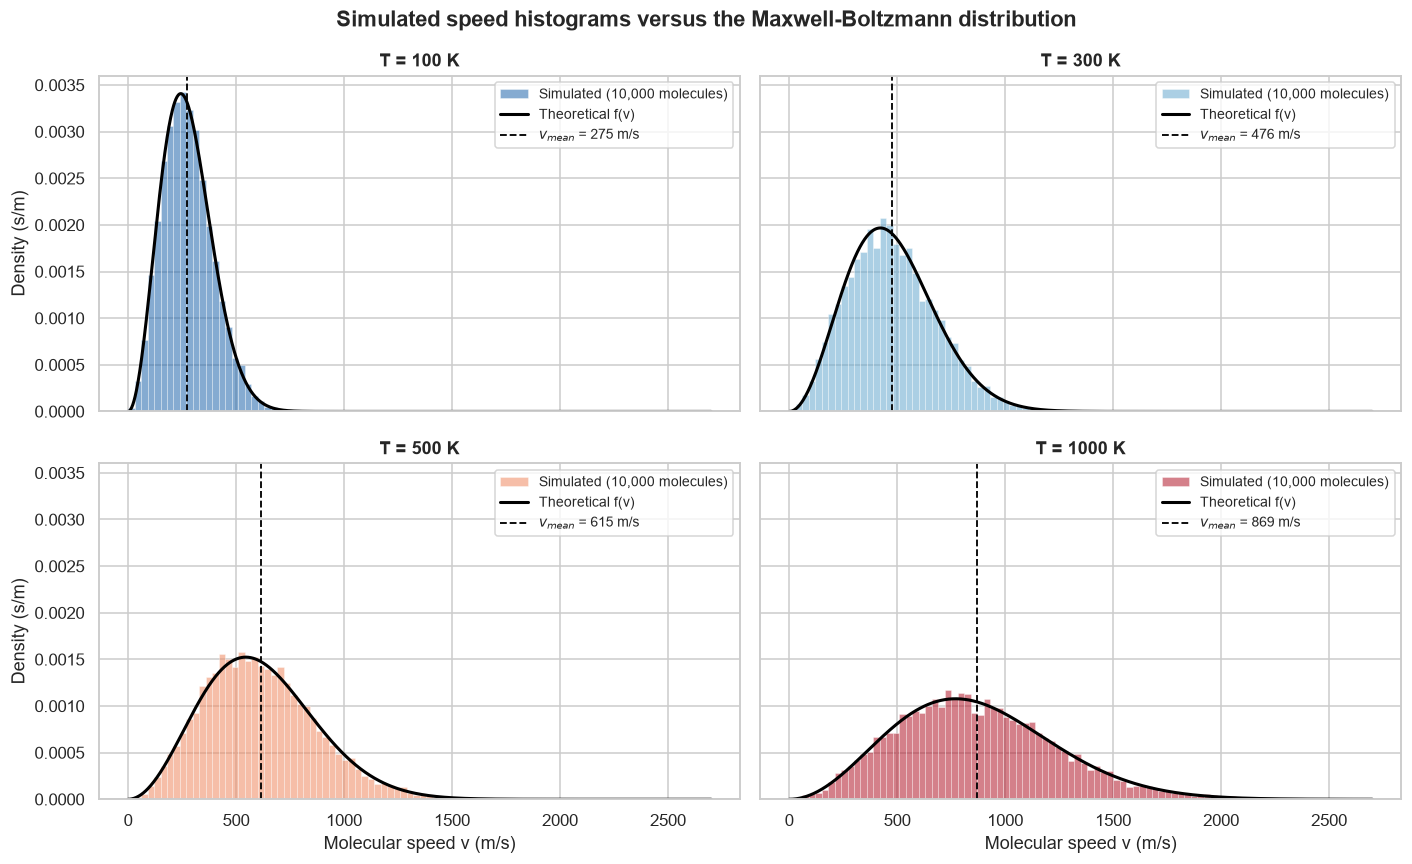

In [20]:
bins = np.linspace(0, 2700, 91)            # 30 m/s bins, same for every temperature
v = np.linspace(0, 2700, 1000)

fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True, sharey=True)
for ax, T in zip(axes.flat, TEMPERATURES):
    speeds = data.loc[data["Temperature"] == T, "Speed"]
    ax.hist(speeds, bins=bins, density=True, color=TEMP_COLORS[T], alpha=0.55,
            edgecolor="white", linewidth=0.4, label="Simulated (10,000 molecules)")
    ax.plot(v, maxwell_pdf(v, T), color="black", lw=2, label="Theoretical f(v)")
    ax.axvline(v_mean_theory(T), color="black", ls="--", lw=1.2,
               label=f"$v_{{mean}}$ = {v_mean_theory(T):.0f} m/s")
    ax.set_title(f"T = {T} K")
    ax.legend(fontsize=9)
for ax in axes[1]:
    ax.set_xlabel("Molecular speed v (m/s)")
for ax in axes[:, 0]:
    ax.set_ylabel("Density (s/m)")
fig.suptitle("Simulated speed histograms versus the Maxwell-Boltzmann distribution", fontweight="bold")
plt.tight_layout()
fig.savefig(f"{FIG_DIR}/fig_6_2_histograms.png", bbox_inches="tight")
plt.show()

**Interpretation.** RESULT_6_2

### 6.3 KDE Comparison of the Four Temperatures

*To be written.*

### 6.4 Boxplots

*To be written.*

### 6.5 Violin Plots

*To be written.*

### 6.6 Mean and RMS Speed versus Temperature

*To be written.*

### 6.7 Kinetic Energy Distributions

*To be written.*

### 6.8 Theoretical versus Simulated Speeds (Q-Q Plot)

*To be written.*

### 6.9 The Universal Curve $v / v_{mp}$

*To be written.*

### 6.10 Correlation Heatmap

*To be written.*

### 6.11 Summary of the EDA

*To be written.*

## 7. Statistical Analysis and Validation

### 7.1 Descriptive Statistics in Depth

*To be written.*

### 7.2 Shapiro-Wilk Test

*To be written.*

### 7.3 Kolmogorov-Smirnov Test

*To be written.*

### 7.4 Maximum Likelihood: Recovering the Temperature

*To be written.*

### 7.5 Sample-Size Effects and Limitations of Testing

*To be written.*


## 8. Feature Engineering

### 8.1 Physics-Based Features and Redundancy

*To be written.*

### 8.2 Target Leakage Check

*To be written.*

### 8.3 Sample-Level Statistical Features

*To be written.*

### 8.4 Final Feature Sets

*To be written.*


## 9. Machine Learning

### 9.1 Linear Regression: Mean Speed versus Temperature

*To be written.*

### 9.2 Random Forest Classifier

*To be written.*

### 9.3 K-Means Clustering

*To be written.*

### 9.4 Additional Algorithms

*To be written.*


## 10. Model Evaluation and Comparison

### 10.1 Cross-Validation with Pipelines

*To be written.*

### 10.2 Comparison of Models

*To be written.*

### 10.3 Is the Model Learning Physics or the Simulator?

*To be written.*


## 11. PCA and Dimensionality Reduction

### 11.1 Standardisation

*To be written.*

### 11.2 Covariance Matrix, Eigenvalues and Eigenvectors

*To be written.*

### 11.3 PCA with scikit-learn

*To be written.*

### 11.4 Explained Variance

*To be written.*

### 11.5 Two-Dimensional Visualisation

*To be written.*

### 11.6 Loadings and Physical Meaning

*To be written.*

### 11.7 Classification on PCA Features (RQ2)

*To be written.*


## 12. Physical Interpretation of Results

*To be written.*

## 13. Discussion

*To be written.*

## 14. Limitations

*To be written.*

## 15. Conclusion

*To be written.*

## 16. References

*To be written.*